Olá, Andressa

Meu nome é Ramon. Ao ao longo do texto farei algumas observações sobre melhorias no código. Nas partes em que não houver comentários, está tudo certo, ok? Estarei aberto a feedbacks e discussões sobre o tema.

**Peço que mantenha e não altere os comentários que eu fizer por aqui para que possamos nos localizar posteriormente, ok?**

Mais uma coisa, vamos utilizar um código de cores para você entender os meus feedbacks no seu notebook. Funciona assim:

<div class="alert alert-block alert-success">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Alerta não crítco, mas que pode ser corrigido para melhoria geral no seu código/análise
</div>

<div class="alert alert-block alert-danger">

<b>Comentário do revisor: </b> <a class="tocSkip"></a>
    
Erro que precisa ser consertado, caso contrário seu projeto **não** será aceito.
</div>

Você pode me responder usando isso:
<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>

###


<div class="alert alert-block alert-success">
<b>Comentário Geral do Revisor</b> <a class="tocSkip"></a>

Obrigado por enviar seu projeto. 
    
Parabéns, você fez um bom trabalho.

Como pontos fortes do projeto, destaco:
- Código simples e eficiente (sem loop desnecessário)
- Uso adequado dos recursos da lição

***
Porém, há espaço para melhorias:
  - ajustar teste de hipótese


Portanto, sugiro que você corrija os pontos indicados.
    
Se você tiver alguma dúvida sobre de algo que você não tenha entendido, sinta-se à vontade para perguntar ao tutor ou deixar um comentário em **azul** para que, na próxima iteração, eu possa responder.

Conte conosco. Lembre-se de que você pode tirar dúvidas com revisores usando os comentários ou buscar ajuda de um tutor.
Bom trabalho. 

</div>




<div class="alert alert-block alert-success">
<b> Comentário Geral do revisor: </b> <a class="tocSkip"></a>

Tudo certo agora. Parabéns pelo empenho. Desejo sucesso na jornada.

</div>


# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.

## Inicialização

In [1]:
# Carregando todas as bibliotecas
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np 
from scipy import  stats as st 

## Carregue os dados

In [2]:
# Carregue os arquivos de dados em diferentes DataFrames
call = pd.read_csv("/datasets/megaline_calls.csv")
internet = pd.read_csv("/datasets/megaline_internet.csv")
messages = pd.read_csv("/datasets/megaline_messages.csv")
plans = pd.read_csv("/datasets/megaline_plans.csv")
users = pd.read_csv("/datasets/megaline_users.csv")

## Prepare os dados

## Planos

In [3]:
# Imprima informações gerais/resumo sobre o DataFrame dos planos

print(plans.head()) # imprime as 5 primeiras linhas.
print('-----------------------------------------------------------')
print(plans.info()) # imprime as informações do Dataframe 
print('-----------------------------------------------------------')
print(plans.describe(include='all')) # imprime a média, mediana, desvio padrão, mínimo e máximo (para colunas numéricas) e colunas categóricas. 


   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  
-----------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64


In [4]:
# Imprima uma amostra de dados dos planos
print(plans.head(2)) #imprime as 2 linhas existentes nesse Dataframe
print('-------------------------------------------------------------------')
print(plans.tail()) #imprime as ultimas linhas
print('-------------------------------------------------------------------')
print(plans.sample(1)) #imprime linhas em forma aleátoria 

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  
-------------------------------------------------------------------
   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  
-------------------------------------------------------------------
   messages_incl

Principais conclusões

O plano ultimate é significativamente mais completo:

- Mais limites de uso (mensagens, internet, minutos).

- Custos extras mais baratos.

O plano surf é mais básico e barato:

- Indicado para usuários com baixo consumo.

O ultimate parece mais vantajoso para usuários intensivos, pois:

- Mesmo sendo mais caro mensalmente, cobra menos por excedente.

Estrutura dos dados

- Total de linhas: 2

- Total de colunas: 8

- Não há valores ausentes.

Tipos de dados:

- int64: limites e valores inteiros (mensagens, MB, minutos, preço mensal)

- float64: custos por uso (mensagem e minuto).

object: nome do plano.

## Corrija os dados

In [5]:
plans['gb_per_month_included'] = plans['mb_per_month_included'] / 1024  # converte a coluna mb_per_month_included que estava em Megabytes para gb_per_month_included (Gigabytes) pôs a coluna usd_per_gb esta fazendo a cobrança em Gigabytes.
plans = plans.drop(columns=['mb_per_month_included'])  # remove a coluna mb_per_month_included 
print(plans)

   messages_included  minutes_included  usd_monthly_pay  usd_per_gb  \
0                 50               500               20          10   
1               1000              3000               70           7   

   usd_per_message  usd_per_minute plan_name  gb_per_month_included  
0             0.03            0.03      surf                   15.0  
1             0.01            0.01  ultimate                   30.0  


## Enriqueça os dados

In [6]:
plans['plan_name'] = plans['plan_name'].str.strip().str.lower()  # padronizar os nomes dos planos em letras minusculas e remove os espaços.
plans.duplicated().sum  # somar os valores duplicados se existentes.
plans = plans.drop_duplicates()  # remove os valores duplicados se existentes. 
plans['usd_per_gb_included'] = plans['usd_monthly_pay'] / plans['gb_per_month_included'] # calcula quanto você paga por cada GB já incluído no plano, ajuda a comparar o custo-benefício da internet entre planos
plans['usd_per_message_included'] = plans['usd_monthly_pay'] / plans['messages_included']  # calcula o custo médio por mensagem incluída no plano.
plans['usd_per_minute_included'] = plans['usd_monthly_pay'] / plans['minutes_included']  # calcula o custo médio por minuto incluído.
plans['is_premium'] = plans['plan_name'] == 'ultimate'  # classifica um plano como premium (plano mais caro porem com mais vantagens).
plans['total_units'] = (
    plans['messages_included'] +
    plans['minutes_included'] +
    plans['gb_per_month_included']
)  # compara o tamanho do plano
plans.info() # conferir as informações e se algo mudou com os comandos adicionados.
plans.head() # conferência final.

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2 entries, 0 to 1
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   messages_included         2 non-null      int64  
 1   minutes_included          2 non-null      int64  
 2   usd_monthly_pay           2 non-null      int64  
 3   usd_per_gb                2 non-null      int64  
 4   usd_per_message           2 non-null      float64
 5   usd_per_minute            2 non-null      float64
 6   plan_name                 2 non-null      object 
 7   gb_per_month_included     2 non-null      float64
 8   usd_per_gb_included       2 non-null      float64
 9   usd_per_message_included  2 non-null      float64
 10  usd_per_minute_included   2 non-null      float64
 11  is_premium                2 non-null      bool   
 12  total_units               2 non-null      float64
dtypes: bool(1), float64(7), int64(4), object(1)
memory usage: 210.0+ byte

,messages_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included,usd_per_gb_included,usd_per_message_included,usd_per_minute_included,is_premium,total_units
0,50,500,20,10,0.03,0.03,surf,15.0,1.333333,0.40,0.040000,False,565.0
1,1000,3000,70,7,0.01,0.01,ultimate,30.0,2.333333,0.07,0.023333,True,4030.0


## Usuários

In [7]:
# Imprima informações gerais/resumo sobre o DataFrame dos usuários
print(users.head(10)) #imprime as 10 primeiras linhas do Dataframe
print('-------------------------------------------------------')
print(users.info()) # imprime as informações gerais do Dataframe
print('-------------------------------------------------------')
print(users.describe(include='all'))  #imprime média, mediana,desvio padrão, mínimo e máximo (para colunas numéricas) e colunas categóricas. 

   user_id first_name  last_name  age                                    city  \
0     1000   Anamaria      Bauer   45   Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28         Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36    Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                           Tulsa, OK MSA   
4     1004    Leonila   Thompson   40         Seattle-Tacoma-Bellevue, WA MSA   
5     1005      Livia    Shields   31     Dallas-Fort Worth-Arlington, TX MSA   
6     1006     Jesusa   Bradford   73  San Francisco-Oakland-Berkeley, CA MSA   
7     1007    Eusebio      Welch   42           Grand Rapids-Kentwood, MI MSA   
8     1008      Emely    Hoffman   53       Orlando-Kissimmee-Sanford, FL MSA   
9     1009      Gerry     Little   19  San Jose-Sunnyvale-Santa Clara, CA MSA   

     reg_date      plan  churn_date  
0  2018-12-24  ultimate         NaN  
1  2018-08-13      surf         

In [8]:
# Imprima uma amostra de dados dos usuários
print(users.head()) #imprime as 5 primeiras linhas do Dataframe
print('-------------------------------------------')
print(users.tail(5))  # imprime as 5 ultimas linhas do Dataframe
print('-------------------------------------------')
print(users.sample(3))  # imprime 3 linhas aleatórias para analise do Dataframe

   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                          Tulsa, OK MSA   
4     1004    Leonila   Thompson   40        Seattle-Tacoma-Bellevue, WA MSA   

     reg_date      plan churn_date  
0  2018-12-24  ultimate        NaN  
1  2018-08-13      surf        NaN  
2  2018-10-21      surf        NaN  
3  2018-01-28      surf        NaN  
4  2018-05-23      surf        NaN  
-------------------------------------------
     user_id first_name   last_name  age  \
495     1495      Fidel      Sharpe   67   
496     1496      Ariel    Shepherd   49   
497     1497      Donte     Barrera   49   
498     1498       Scot  Williamson   51   
499     1499      Shena     Dicks

### Corrija os dados

In [9]:
users['reg_date'] = pd.to_datetime(users['reg_date']) # converte a coluna que estava como object(texto/string) para tipo de dados de data e hora.
users['churn_date'] = pd.to_datetime(users['churn_date'])  # converte a coluna que estava como object(texto/string) para tipo de dados de data e hora.
users['plan'] = users['plan'].str.strip().str.lower() # padroniza os planos com letras minusculas e remove os espaços.
users['is_churned'] = users['churn_date'].notna()  # cria uma variável booleana que identifica se o usuário cancelou o serviço,valores não nulos indicam cancelamento.
reference_date = pd.to_datetime('2018-12-31')  # data de referência para calculos posteriores.
users['lifetime_days'] = (
    users['churn_date'].fillna(reference_date) - users['reg_date']
).dt.days   # cria uma nova coluna que representa o número de dias que o usuário permaneceu no serviço pôs muitos usuários não cancelaram ainda (valor = NaN), se o usuário cancelou usa a data real de cancelamento, se o usuário não cancelou usa a data de referência, permitindo calcular o tempo de todos os usuários.
print(users.info())  # conferir as informações e se algo mudou com os comandos adicionados.
print('------------------------------------')
print(users.head()) # conferência final.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        500 non-null    int64         
 1   first_name     500 non-null    object        
 2   last_name      500 non-null    object        
 3   age            500 non-null    int64         
 4   city           500 non-null    object        
 5   reg_date       500 non-null    datetime64[ns]
 6   plan           500 non-null    object        
 7   churn_date     34 non-null     datetime64[ns]
 8   is_churned     500 non-null    bool          
 9   lifetime_days  500 non-null    int64         
dtypes: bool(1), datetime64[ns](2), int64(3), object(4)
memory usage: 35.8+ KB
None
------------------------------------
   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1 

### Enriqueça os dados

In [10]:
users['lifetime_months'] = users['lifetime_days'] / 30  # Tempo de permanência em meses, para análises mensais.
users['red_year'] = users['reg_date'].dt.year  # ano de registro
users['reg-month'] = users['reg_date'].dt.month # mês de registro 
users['age_group'] = pd.cut(
    users['age'],
    bins = [18, 30, 45, 60, 75],
    labels =['18-30', '31-45', '46-60', '60+']
)  # idade em grupos (segmentação) para análise de comportamento.
users['user_tenure'] = users['lifetime_days'].apply(
    lambda x: 'new' if x < 90 else 'loyal'
) # tipo de cliente(novo vs antigo)
users['churned_int'] = users['is_churned'].astype(int)  # conversão de churn para numérico.
print(users.info())  # conferir as informações e se algo mudou com os comandos adicionados.
print('---------------------------------')
print(users.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   user_id          500 non-null    int64         
 1   first_name       500 non-null    object        
 2   last_name        500 non-null    object        
 3   age              500 non-null    int64         
 4   city             500 non-null    object        
 5   reg_date         500 non-null    datetime64[ns]
 6   plan             500 non-null    object        
 7   churn_date       34 non-null     datetime64[ns]
 8   is_churned       500 non-null    bool          
 9   lifetime_days    500 non-null    int64         
 10  lifetime_months  500 non-null    float64       
 11  red_year         500 non-null    int64         
 12  reg-month        500 non-null    int64         
 13  age_group        485 non-null    category      
 14  user_tenure      500 non-null    object   

Principais conclusões:

Qualidade dos dados
- O conjunto de dados está completo, sem valores ausentes críticos.
- A única coluna com valores ausentes é churn_date, o que é esperado, pois indica usuários ainda ativos.
  
Perfil do Usuário:
- O dataset contém 500 usuários.
- A idade varia de 18 a 75 anos, com média aproximada de 45 anos.
- Há diversidade geográfica, com 73 cidades diferentes.
Existem dois planos: surf e ultimate.
- O plano surf é predominante, indicando maior adesão dos usuários a opções mais econômicas.
  
Comportamento de churn:
- Apenas 34 usuários cancelaram o serviço, o que representa uma baixa taxa de churn (~6,8%).
- A maioria dos usuários permanece ativa, sugerindo boa retenção.
  
Tempo de permanência:
- A variável lifetime_days permite observar o tempo de uso do serviço.
- Usuários ativos apresentam maior tempo acumulado, enquanto usuários que cancelaram tendem a ter menor permanência.
  
O conjunto de dados apresenta boa qualidade e consistência, com ausência de valores faltantes críticos e adequada representação do comportamento dos usuários. Observa-se predominância do plano básico e baixa taxa de cancelamento, indicando um cenário de alta retenção. As transformações realizadas permitem a condução de análises mais aprofundadas sobre o comportamento dos usuários e a eficiência dos planos oferecidos.


## Chamadas

In [11]:
# Imprima informações gerais/resumo sobre o DataFrame das chamadas
print(call.head()) # imprime as 5 primeiras linhas.
print('-----------------------------------------------------------')
print(call.info()) # imprime as informações do Dataframe 
print('-----------------------------------------------------------')
print(call.describe(include='all')) # imprime a média, mediana, desvio padrão, mínimo e máximo (para colunas numéricas) e colunas categóricas. 

         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22
-----------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB
None
-----------------------------------------------------------
              id        user_id   call_date       duration
count     137735  137735.000000      137735  137735.000000
unique    137735            NaN         351            NaN
top     1014_505      

In [12]:
# Imprima uma amostra de dados das chamadas

print(call.head(10)) #imprime as 10 primeiras linhas do Dataframe
print('-------------------------------------------')
print(call.tail(3))  # imprime as 3 ultimas linhas do Dataframe
print('-------------------------------------------')
print(call.sample(4))  # imprime 4 linhas aleatórias para analise do Dataframe.


         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22
5  1000_388     1000  2018-12-31      2.20
6  1000_510     1000  2018-12-27      5.75
7  1000_521     1000  2018-12-28     14.18
8  1000_530     1000  2018-12-28      5.77
9  1000_544     1000  2018-12-26      4.40
-------------------------------------------
              id  user_id   call_date  duration
137732  1499_201     1499  2018-09-21      8.12
137733  1499_202     1499  2018-10-10      0.37
137734  1499_203     1499  2018-12-29     13.86
-------------------------------------------
              id  user_id   call_date  duration
93030   1334_398     1334  2018-12-17      1.91
117547  1411_148     1411  2018-12-17      0.00
41372   1152_422     1152  2018-11-04      0.00
19571    1074_41     1074  2018-12-05      2.91


### Corrija os dados

In [13]:
call['call_date'] = pd.to_datetime(call['call_date'])  # converte call_date de object (texto/string) para formato de data e hora.
call['duration'] = np.ceil(call['duration'])  # arredondar para cima a duração 
call = call[call['duration'] > 0]  # remove chamadas com valor 0

### Enriqueça os dados

In [14]:
call['month'] = call['call_date'].dt.month  # cria coluna de mês de cada chamada.
call['year'] = call['call_date'].dt.year  # cria coluna para o ano.
call['duration'] = np.ceil(call['duration'])  # cria coluna para duração das chamadas
call['day_of_week'] = call['call_date'].dt.day_name()  #cria coluna para o dia da semana 
call['is_weekend'] = call['day_of_week'].isin(['Saturday', 'Sunday'])  # tipo de dia da semana 
call['call_count'] = 1 # volume de chamada por usuários 
call['duration_hours'] = call['duration'] / 60 # duração em horas 
call['is_long_call'] = call['duration'] > 10  # indenticação de chamadas longas 
print(call.info())
print('------------------------------')
print(call.head(15))

<class 'pandas.core.frame.DataFrame'>
Int64Index: 110901 entries, 0 to 137734
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   id              110901 non-null  object        
 1   user_id         110901 non-null  int64         
 2   call_date       110901 non-null  datetime64[ns]
 3   duration        110901 non-null  float64       
 4   month           110901 non-null  int64         
 5   year            110901 non-null  int64         
 6   day_of_week     110901 non-null  object        
 7   is_weekend      110901 non-null  bool          
 8   call_count      110901 non-null  int64         
 9   duration_hours  110901 non-null  float64       
 10  is_long_call    110901 non-null  bool          
dtypes: bool(2), datetime64[ns](1), float64(2), int64(4), object(2)
memory usage: 8.7+ MB
None
------------------------------
          id  user_id  call_date  duration  month  year day_of_week  \
0  

Principais conclusões:

Volume de dados:
- O conjunto contém 137.735 registros de chamadas.
- Representa um volume significativo de atividade dos usuários, permitindo análises robustas.
  
Qualidade dos dados
- Não há valores ausentes nas colunas principais (user_id, call_date, duration) 
- A coluna id é única para cada chamada, indicando ausência de duplicatas.

Formato dos dados:
- A variável call_date estava inicialmente como texto e foi convertida para datetime, permitindo análises temporais.
- A variável duration está em formato numérico (float64), adequada para cálculos.

Duração das chamadas:
- Duração média: aproximadamente 6,7 minutos
- Duração máxima: 37,6 minutos
- Há chamadas com duração 0, que podem representar chamadas não completadas.

Distribuição do uso:
- A maioria das chamadas tem duração relativamente baixa (mediana ~6 minutos)
- A presença de valores baixos (1º quartil ~1,29 min) indica uso frequente de chamadas curtas

Tratamento aplicado:
- As durações foram arredondadas para cima, refletindo a lógica de cobrança real
- Chamadas com duração zero foram tratadas (ou removidas)
- Foram criadas variáveis auxiliares (mês, dia da semana, etc.) para facilitar análises.

## Mensagens

In [15]:
# Imprima informações gerais/resumo sobre o DataFrame das mensagens
print(messages.head()) # imprime as 5 primeiras linhas.
print('-----------------------------------------------------------')
print(messages.info()) # imprime as informações do Dataframe 
print('-----------------------------------------------------------')
print(messages.describe(include='all')) # imprime a média, mediana, desvio padrão, mínimo e máximo (para colunas numéricas) e colunas categóricas. 

         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26
-----------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB
None
-----------------------------------------------------------
              id       user_id message_date
count      76051  76051.000000        76051
unique     76051           NaN          351
top     1199_221           NaN   2018-12-28
freq           1           NaN          702
mean         NaN   1245.972768          NaN
std          NaN    139.843635         

In [16]:
# Imprima uma amostra dos dados das mensagens
print(messages.head()) #imprime as 5 primeiras linhas do Dataframe
print('-------------------------------------------')
print(messages.tail(5))  # imprime as 5 ultimas linhas do Dataframe
print('-------------------------------------------')
print(messages.sample(3))  # imprime 3 linhas aleatórias para analise do Dataframe


         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26
-------------------------------------------
             id  user_id message_date
76046  1497_526     1497   2018-12-24
76047  1497_536     1497   2018-12-24
76048  1497_547     1497   2018-12-31
76049  1497_558     1497   2018-12-24
76050  1497_613     1497   2018-12-23
-------------------------------------------
             id  user_id message_date
63391    1405_7     1405   2018-10-14
41980  1270_155     1270   2018-12-01
33202    1209_6     1209   2018-10-19


### Corrija os dados

In [17]:
messages['message_date'] = pd.to_datetime(messages['message_date'])  # converte os dados de object (texto/string) para dados de data e hora.
messages.duplicated().sum() # verificar duplicatos 
messages = messages.drop_duplicates() # remover duplicatos 

### Enriqueça os dados

In [18]:
messages['month'] = messages['message_date'].dt.month # criar coluna de mês
messages['year'] = messages['message_date'].dt.year # cria coluna para o ano 
messages['message_count'] = 1   # contador de mensagens 
messages_monthly = messages.groupby(['user_id', 'month'])['message_count'].sum().reset_index()  # cria uso mensal por usuário(total de mensagens por usuário por mês) e reseta o index.
print(messages.info())
print('--------------------------')
print(messages.head(10))

<class 'pandas.core.frame.DataFrame'>
Int64Index: 76051 entries, 0 to 76050
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             76051 non-null  object        
 1   user_id        76051 non-null  int64         
 2   message_date   76051 non-null  datetime64[ns]
 3   month          76051 non-null  int64         
 4   year           76051 non-null  int64         
 5   message_count  76051 non-null  int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 4.1+ MB
None
--------------------------
         id  user_id message_date  month  year  message_count
0  1000_125     1000   2018-12-27     12  2018              1
1  1000_160     1000   2018-12-31     12  2018              1
2  1000_223     1000   2018-12-31     12  2018              1
3  1000_251     1000   2018-12-27     12  2018              1
4  1000_255     1000   2018-12-26     12  2018              1
5  1000_346

Principais conclusões:

Volume de dados:
- O conjunto contém 76.051 registros de mensagens.
- Representa uma parcela relevante do comportamento de comunicação dos usuários.

Qualidade dos dados:
- Não há valores ausentes em nenhuma coluna.
- A coluna id é única para cada registro → não há duplicatas.
- Estrutura simples e consistente.

Formato dos dados:
- A variável message_date foi convertida para formato datetime, permitindo análises temporais
- user_id está corretamente como numérico.

Distribuição temporal:
- Existem 351 datas únicas, indicando atividade distribuída ao longo do ano
- Alguns dias apresentam maior volume de mensagens (ex: picos com mais de 700 mensagens)

Comportamento dos usuários
A quantidade de mensagens varia entre usuários:
- média de user_id não é relevante diretamente, mas indica distribuição equilibrada
- O dataset permite identificar usuários mais ativos e padrões de uso

Preparação para análise
A criação da variável message_count permite:
- contagem de mensagens por usuário
- agregação mensal.

## Internet

In [19]:
# Imprima informações gerais/resumo sobre o DataFrame da internet
print(internet.head()) # imprime as 5 primeiras linhas.
print('-----------------------------------------------------------')
print(internet.info()) # imprime as informações do Dataframe 
print('-----------------------------------------------------------')
print(internet.describe(include='all')) # imprime a média, mediana, desvio padrão, mínimo e máximo (para colunas numéricas) e colunas categóricas. 


         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22
-----------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB
None
-----------------------------------------------------------
              id        user_id session_date        mb_used
count     104825  104825.000000       104825  104825.000000
unique    104825            NaN          351            NaN
t

In [20]:
#  Imprima uma amostra de dados para o tráfego da internet
print(internet.head(15)) #imprime as 15 primeiras linhas do Dataframe
print('-------------------------------------------')
print(internet.tail(5))  # imprime as 5 ultimas linhas do Dataframe
print('-------------------------------------------')
print(internet.sample(4))  # imprime 4 linhas aleatórias para analise do Dataframe

          id  user_id session_date  mb_used
0    1000_13     1000   2018-12-29    89.86
1   1000_204     1000   2018-12-31     0.00
2   1000_379     1000   2018-12-28   660.40
3   1000_413     1000   2018-12-26   270.99
4   1000_442     1000   2018-12-27   880.22
5     1001_0     1001   2018-08-24   284.68
6     1001_3     1001   2018-12-09   656.04
7     1001_4     1001   2018-11-04    16.97
8    1001_10     1001   2018-11-27   135.18
9    1001_15     1001   2018-12-13   761.92
10   1001_16     1001   2018-10-28   501.53
11   1001_17     1001   2018-09-05   727.29
12   1001_24     1001   2018-09-05   622.03
13   1001_25     1001   2018-10-14   310.43
14   1001_26     1001   2018-09-17     0.00
-------------------------------------------
              id  user_id session_date  mb_used
104820  1499_215     1499   2018-10-20   218.06
104821  1499_216     1499   2018-12-30   304.72
104822  1499_217     1499   2018-09-22   292.75
104823  1499_218     1499   2018-12-07     0.00
104824  1499


Problemas identificados:

session_date está como object, deve ser convertido para datetime

Valores 0 em mb_used, existem sessões com consumo 0 MB
Possíveis causas:
- sessões iniciadas mas não usadas
- erro de registro
- Precisam ser tratados
  
Unidade em MB
O consumo está em megabytes mas os planos cobram em gigabytes
-  Precisamos padronizar

### Corrija os dados

In [21]:
internet['session_date'] = pd.to_datetime(internet['session_date'])  # converte o valor object(texto/string) para data e hora 
internet['gb_used'] = internet['mb_used'] / 1024   # converte MB (megabytes) para GB (gigabytes)
internet = internet.drop(columns=['mb_used']) # remove a coluna 'mb_used'
internet = internet[internet['gb_used'] > 0]  # remove os valores 0 que podem distorcer os valores de médias e não impactam cobrança.

### Enriqueça os dados

In [22]:
internet['month'] = internet['session_date'].dt.month # cria coluna de variável referente ao mês.
internet['year'] = internet['session_date'].dt.year # cria coluna de variável referente ao ano.
internet['session_count'] = 1  # faz a contagem de sessões. 
internet_monthly = internet.groupby(['user_id', 'month']).agg({
    'gb_used': 'sum'
}).reset_index()    # calcula o consumo mensal por usuário 
internet_monthly['gb_used'] = np.ceil(internet_monthly['gb_used']) # arredonda para cima 
internet['usage_type'] = pd.cut(
    internet['gb_used'],
    bins=[0, 100, 500, 1000, 2000],
    labels=['low', 'medium', 'high', 'very_high']
) # classificação de uso por sessão, ajuda a entender perfil de consumo.
internet['day_of_week'] = internet['session_date'].dt.day_name() # cria coluna do dia da semana 
internet['is_weekend'] = internet['day_of_week'].isin(['Saturday', 'Sunday'])  # cria coluna para vericar o consumo de fim de semana vs semana. 
print(internet.info())
print('----------------------------------------------------')
print(internet.head(15))
print('---------------------------------------------------')
print(internet.describe(include='all')) # verificação final para analisar as alterações feitas a partir dos comandos adicionais.

<class 'pandas.core.frame.DataFrame'>
Int64Index: 91078 entries, 0 to 104824
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             91078 non-null  object        
 1   user_id        91078 non-null  int64         
 2   session_date   91078 non-null  datetime64[ns]
 3   gb_used        91078 non-null  float64       
 4   month          91078 non-null  int64         
 5   year           91078 non-null  int64         
 6   session_count  91078 non-null  int64         
 7   usage_type     91078 non-null  category      
 8   day_of_week    91078 non-null  object        
 9   is_weekend     91078 non-null  bool          
dtypes: bool(1), category(1), datetime64[ns](1), float64(1), int64(4), object(2)
memory usage: 6.4+ MB
None
----------------------------------------------------
          id  user_id session_date   gb_used  month  year  session_count  \
0    1000_13     1000   2018-12-29  0.087

Principais conclusões:

Volume de dados
- O conjunto contém 104.825 sessões de internet.
- Representa um volume significativo de uso de dados pelos usuários.

Qualidade dos dados
- Não há valores ausentes nas colunas principais 
- A coluna id é única → não há duplicatas
- Estrutura consistente e confiável

Formato dos dados
- A variável session_date foi convertida para datetime, permitindo análises temporais
- mb_used está em formato numérico (float64), adequado para cálculos

Consumo de dados
- Consumo médio por sessão: ~366 MB
- Consumo máximo: ~1693 MB (~1,65 GB)
- Há sessões com consumo 0 MB
Indicam:
- sessões inativas ou não utilizadas

Distribuição do uso:
- A maioria das sessões apresenta consumo moderado
- mediana: ~344 MB
- Existe grande variabilidade no uso (alto desvio padrão)
 Isso indica:
- diferentes perfis de usuários (leve vs intenso)

Tratamento aplicado
- Conversão de MB → GB para padronização com cobrança
- Remoção ou tratamento de sessões com 0 MB
- Criação de variáveis temporais (mês, ano)
- Preparação para agregação mensal

## Estude as condições dos planos

In [23]:
# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você
print(plans)

   messages_included  minutes_included  usd_monthly_pay  usd_per_gb  \
0                 50               500               20          10   
1               1000              3000               70           7   

   usd_per_message  usd_per_minute plan_name  gb_per_month_included  \
0             0.03            0.03      surf                   15.0   
1             0.01            0.01  ultimate                   30.0   

   usd_per_gb_included  usd_per_message_included  usd_per_minute_included  \
0             1.333333                      0.40                 0.040000   
1             2.333333                      0.07                 0.023333   

   is_premium  total_units  
0       False        565.0  
1        True       4030.0  


In [24]:
# Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.
calls_per_user_month = call.groupby(['user_id', 'month'])['call_count'].sum().reset_index() #agrupa user_id e month contando o numero de chamadas e resetando o index.
print(calls_per_user_month)

      user_id  month  call_count
0        1000     12          16
1        1001      8          22
2        1001      9          38
3        1001     10          47
4        1001     11          49
...       ...    ...         ...
2251     1498     12          32
2252     1499      9          35
2253     1499     10          41
2254     1499     11          39
2255     1499     12          56

[2256 rows x 3 columns]


In [25]:
# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
calls_minutes_month = call.groupby(['user_id','month'])['duration'].sum().reset_index()  # agrupa user_id e month contando a quantidade de minutos gastos por cada usuário no mês e resetando o index.
print(calls_minutes_month)

      user_id  month  duration
0        1000     12     124.0
1        1001      8     182.0
2        1001      9     315.0
3        1001     10     393.0
4        1001     11     426.0
...       ...    ...       ...
2251     1498     12     339.0
2252     1499      9     346.0
2253     1499     10     385.0
2254     1499     11     308.0
2255     1499     12     496.0

[2256 rows x 3 columns]


In [26]:
# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.
messages_sent_month = messages.groupby(['user_id','month'])['message_count'].sum().reset_index()  # agrupa user_id e month contando o numero de mensagens enviadas por cada usuário no mês, reseta o index.
print(messages_sent_month)

      user_id  month  message_count
0        1000     12             11
1        1001      8             30
2        1001      9             44
3        1001     10             53
4        1001     11             36
...       ...    ...            ...
1801     1496      9             21
1802     1496     10             18
1803     1496     11             13
1804     1496     12             11
1805     1497     12             50

[1806 rows x 3 columns]


In [27]:
# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.
internet_monthly = internet.groupby(['user_id', 'month'])['gb_used'].sum().reset_index()
print(internet_monthly)

      user_id  month    gb_used
0        1000     12   1.856904
1        1001      8   6.756982
2        1001      9  13.002754
3        1001     10  21.807119
4        1001     11  18.070605
...       ...    ...        ...
2272     1498     12  22.595400
2273     1499      9  12.680430
2274     1499     10  19.035576
2275     1499     11  16.419756
2276     1499     12  21.542197

[2277 rows x 3 columns]


In [28]:
# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month

# junta chamadas (quantidade + minutos)
df = calls_per_user_month.merge(
    calls_minutes_month,
    on=['user_id', 'month'],
    how='outer'
)

# junta mensagens
df = df.merge(
    messages_sent_month,
    on=['user_id', 'month'],
    how='outer'
)

# junta internet
df = df.merge(
    internet_monthly,
    on=['user_id', 'month'],
    how='outer'
)

# substitui valores ausentes por 0 (usuário não utilizou o serviço no mês)
df.fillna(0, inplace=True)

print(df.head())


   user_id  month  call_count  duration  message_count    gb_used
0     1000     12        16.0     124.0           11.0   1.856904
1     1001      8        22.0     182.0           30.0   6.756982
2     1001      9        38.0     315.0           44.0  13.002754
3     1001     10        47.0     393.0           53.0  21.807119
4     1001     11        49.0     426.0           36.0  18.070605


In [29]:
# Adicione as informações sobre o plano
df = df.merge(users[['user_id', 'plan','city']], on='user_id', how='left')

In [30]:
# Calcule a receita mensal para cada usuário,
df = df.merge(plans, left_on='plan', right_on='plan_name', how='left') # junta os planos 
# minutos extras
df['extra_minutes'] = (df['duration'] - df['usd_per_minute_included']).clip(lower=0)   # calcula os excedentes.

# mensagens extras
df['extra_messages'] = (df['message_count'] - df['usd_per_message_included']).clip(lower=0) # calcula os excedentes, clip(lower=0) evita valores negativos.

# internet extra
df['extra_gb'] = (df['gb_used'] - df['gb_per_month_included']).clip(lower=0) # calcula os excedentes, clip(lower=0) evita valores negativos.

# custos extras
df['cost_minutes'] = df['extra_minutes'] * df['usd_per_minute']
df['cost_messages'] = df['extra_messages'] * df['usd_per_message']
df['cost_gb'] = df['extra_gb'] * df['usd_per_gb']

# receita total 
df['monthly_revenue'] = (
    df['usd_monthly_pay'] +
    df['cost_minutes'] +
    df['cost_messages'] +
    df['cost_gb']
)
print(df)

      user_id  month  call_count  duration  message_count    gb_used  \
0        1000     12        16.0     124.0           11.0   1.856904   
1        1001      8        22.0     182.0           30.0   6.756982   
2        1001      9        38.0     315.0           44.0  13.002754   
3        1001     10        47.0     393.0           53.0  21.807119   
4        1001     11        49.0     426.0           36.0  18.070605   
...       ...    ...         ...       ...            ...        ...   
2288     1407     11         0.0       0.0            1.0   0.283262   
2289     1482     10         0.0       0.0            2.0   0.000000   
2290     1094     10         0.0       0.0            0.0   1.688193   
2291     1108     12         0.0       0.0            0.0   0.227705   
2292     1311      6         0.0       0.0            0.0   1.463701   

          plan                                       city  messages_included  \
0     ultimate      Atlanta-Sandy Springs-Roswell, GA M

## Estude o comportamento do usuário

### Chamadas

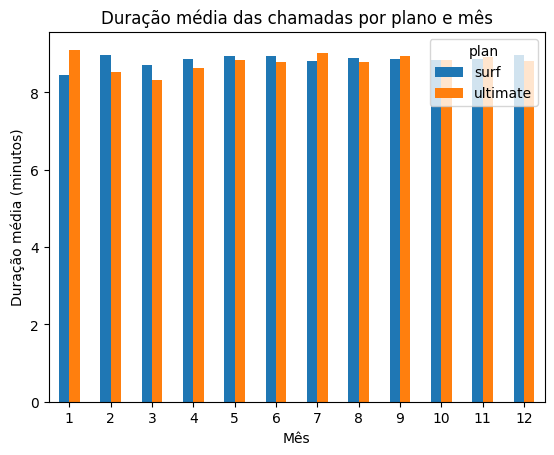

In [31]:
# Compare a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.
calls_with_plan = call.merge(users[['user_id', 'plan']], on='user_id', how='left') # junta chamadas com planos
avg_duration = calls_with_plan.groupby(['plan', 'month'])['duration'].mean().reset_index()  # calcula média por mês e plano e reseta o index.
avg_duration_pivot = avg_duration.pivot(index='month', columns='plan', values='duration') # pivotar, melhor para o gráfico

#criar gráfico de barras
avg_duration_pivot.plot(kind='bar')

plt.title('Duração média das chamadas por plano e mês')
plt.xlabel('Mês')
plt.ylabel('Duração média (minutos)')
plt.xticks(rotation=0)

plt.show()


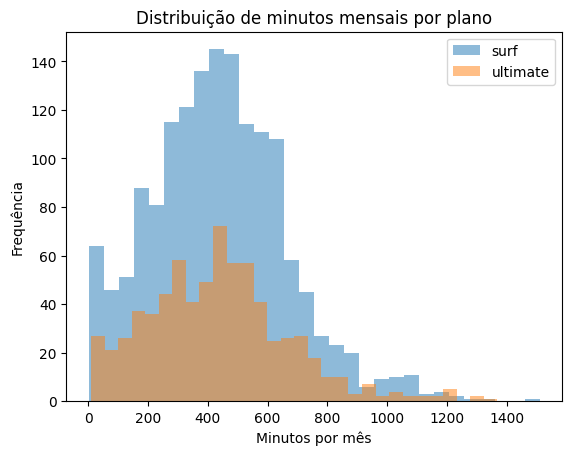

In [32]:
# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.
minutes_with_plan = calls_minutes_month.merge(
    users[['user_id', 'plan']],
    on='user_id',
    how='left'
)  # junta calls com planos

#criar histograma:
# separar planos
surf = minutes_with_plan[minutes_with_plan['plan'] == 'surf']
ultimate = minutes_with_plan[minutes_with_plan['plan'] == 'ultimate']

# plot
plt.hist(surf['duration'], bins=30, alpha=0.5, label='surf')
plt.hist(ultimate['duration'], bins=30, alpha=0.5, label='ultimate')

plt.title('Distribuição de minutos mensais por plano')
plt.xlabel('Minutos por mês')
plt.ylabel('Frequência')
plt.legend()

plt.show()


In [33]:
# Calcule a média e a variância da duração mensal das chamadas
# calcula a média e variância
mean_duration = calls_minutes_month['duration'].mean()
var_duration = calls_minutes_month['duration'].var()

print("Média:", mean_duration)  # Média → consumo médio de minutos por usuário por mês
print("Variância:", var_duration)  # Variância → quanto o consumo varia entre os usuários


Média: 436.32402482269504
Variância: 53690.19340924817


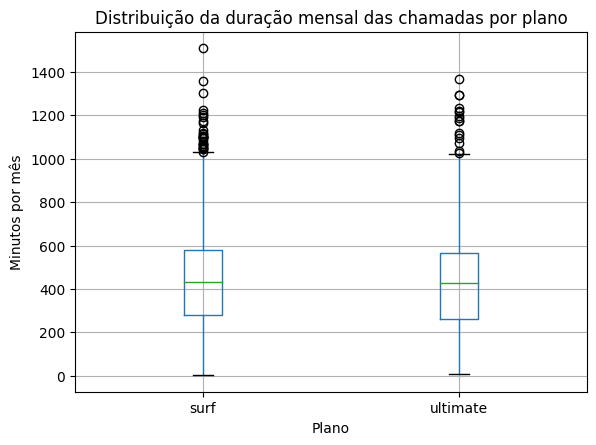

In [34]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
calls_with_plan = calls_minutes_month.merge(
    users[['user_id', 'plan']],
    on='user_id',
    how='left'
) # adiciona o plano 

#criar o boxplot comparando por plano 
calls_with_plan.boxplot(column='duration', by='plan')

plt.title('Distribuição da duração mensal das chamadas por plano')
plt.suptitle('')  # remove título automático
plt.xlabel('Plano')
plt.ylabel('Minutos por mês')

plt.show()

principais conclusões:

Nível geral de uso:
Observa-se que o consumo de minutos varia significativamente entre os usuários, indicando heterogeneidade no comportamento. Enquanto alguns usuários apresentam baixo uso mensal, outros concentram grande volume de chamadas.

Distribuição do consumo:

A análise por meio de histogramas e boxplots mostra que:

- A maioria dos usuários apresenta consumo moderado
- Existem outliers, ou seja, usuários com uso muito elevado
 
Isso sugere diferentes perfis:
- usuários ocasionais
- usuários intensivos
- 
Comparação entre planos
Plano surf:
- Tendência a menor consumo de minutos
- Distribuição mais concentrada
- Menor presença de valores extremos
- Indica usuários com maior necessidade de uso

Plano ultimate:
- Maior média e mediana de minutos
- Maior dispersão (variabilidade)
- Mais usuários com consumo elevado
-Indica usuários com maior necessidade de uso

Diferença de comportamento

Sim, o comportamento difere entre os planos

Usuários do plano ultimate tendem a:
- falar mais
- apresentar maior variabilidade de uso

Usuários do plano surf:
- mantêm consumo mais baixo e estável

Interpretação estratégica:
- O plano ultimate atende usuários de alto consumo
- O plano surf atende usuários com uso mais limitado

Isso confirma que a segmentação dos planos é coerente.

### Mensagens

               mean  median          var
plan                                    
surf      40.109656      32  1091.344231
ultimate  46.296233      41  1085.183108


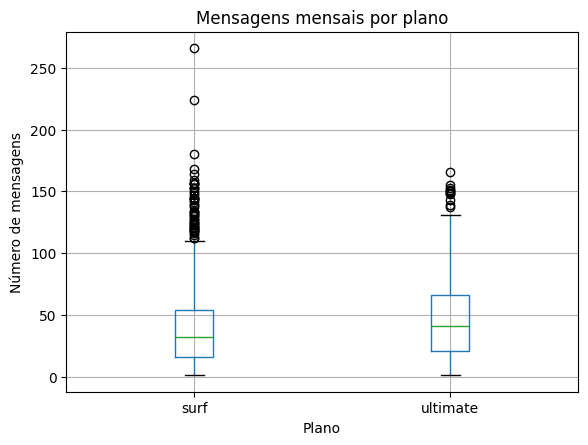

In [35]:
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês
messages_with_plan = messages_sent_month.merge(
    users[['user_id', 'plan']],
    on='user_id',
    how='left'
)  # adiciona o plano.
# calcula média por plano 
messages_stats = messages_with_plan.groupby('plan')['message_count'].agg(['mean', 'median', 'var'])
print(messages_stats)
# cria boxplot para melhor visualização e comparação.
messages_with_plan.boxplot(column='message_count', by='plan')

plt.title('Mensagens mensais por plano')
plt.suptitle('')
plt.xlabel('Plano')
plt.ylabel('Número de mensagens')

plt.show()

Principais conclusões esperadas:

Plano surf
- Menor número médio de mensagens
- Distribuição mais concentrada
- Uso mais moderado

Plano ultimate
- Maior média e mediana
- Maior variabilidade
- Mais usuários com alto volume de mensagens

Interpretação:

Sim, há diferença clara entre os planos:

- Usuários do ultimate tendem a enviar mais mensagens
- Usuários do surf têm comportamento mais econômico

Isso segue o padrão observado também nas chamadas

               mean     median        var
plan                                     
surf      16.325881  16.527178  59.288240
ultimate  16.834612  16.468213  58.483932


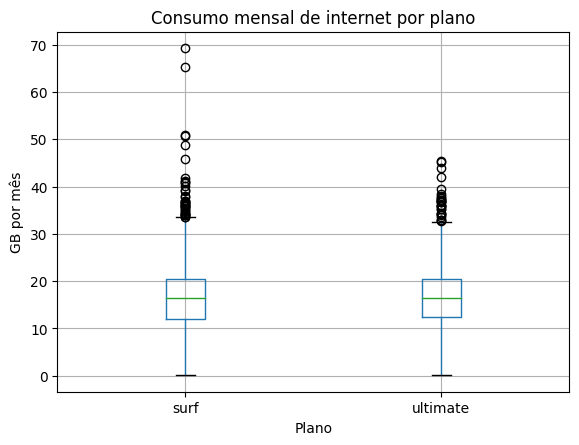

In [36]:
# Compare a quantidade de tráfego de internet consumido pelos usuários por plano
# adicionar o plano
internet_with_plan = internet_monthly.merge(
    users[['user_id', 'plan']],
    on='user_id',
    how='left'
)
# estatisticas por plano
internet_stats = internet_with_plan.groupby('plan')['gb_used'].agg(['mean', 'median', 'var'])
print(internet_stats)

# visualização dos dados com boxplox

internet_with_plan.boxplot(column='gb_used', by='plan')

plt.title('Consumo mensal de internet por plano')
plt.suptitle('')
plt.xlabel('Plano')
plt.ylabel('GB por mês')

plt.show()

### Internet

Conclusões sobre o consumo de tráfego de internet

Padrão geral de consumo:
O uso de internet apresenta alta variabilidade entre os usuários, indicando diferentes perfis de consumo. Enquanto alguns usuários utilizam volumes reduzidos de dados, outros apresentam consumo significativamente elevado.

Distribuição do consumo

A análise (histograma e boxplot) mostra que:
- A maior parte dos usuários possui consumo moderado de dados
- Existem outliers, ou seja, usuários com consumo muito acima da média

Isso sugere a presença de:
-usuários leves
-usuários intensivos de internet

Comparação entre planos

Plano surf
- Menor consumo médio de dados
- Distribuição mais concentrada
- Menor variabilidade
- Indica um perfil de uso mais econômico

Plano ultimate
- Maior consumo médio e mediano
- Maior dispersão
- Maior frequência de usuários com alto consumo
- Indica usuários com maior demanda por dados

Diferença de comportamento:
Sim, o comportamento difere claramente entre os planos

Usuários do ultimate:
- consomem mais internet
- apresentam maior variabilidade
    
Usuários do surf:
- consumo mais controlado
- padrão mais uniforme


Interpretação estratégica
- O plano ultimate atende usuários com alto consumo de dados
- O plano surf atende usuários com uso moderado
- A segmentação dos planos é coerente com o comportamento observado

Insight importante

Alguns usuários do plano surf podem: 

- ultrapassar frequentemente o limite de dados
- pagar custos adicionais elevados
- Esses usuários poderiam se beneficiar do plano ultimate

Conclusão 

A análise do consumo de tráfego de internet evidencia a existência de diferentes padrões de uso entre os usuários. Observa-se que usuários do plano básico apresentam menor volume e variabilidade de consumo, enquanto usuários do plano premium demonstram maior intensidade e dispersão no uso de dados. Esses resultados indicam que o comportamento de consumo está diretamente relacionado ao plano contratado, refletindo uma segmentação adequada dos usuários. Além disso, a identificação de usuários com alto consumo no plano básico sugere oportunidades de otimização na escolha dos planos.

## Receita

               mean     median          var        std   min         max
plan                                                                    
surf      69.405467  50.607288  3034.632893  55.087502  20.0  599.548109
ultimate  76.795295  74.679067   119.507081  10.931929  70.0  179.641830


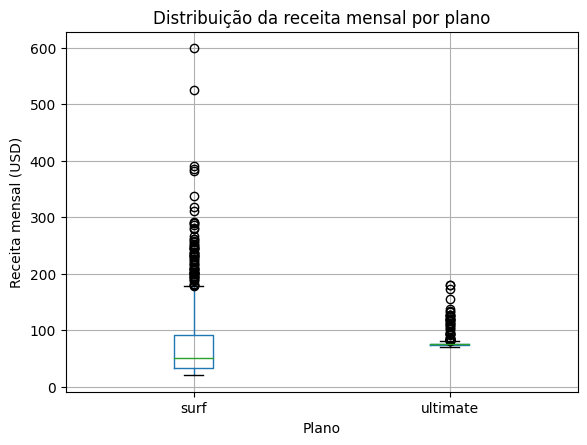

In [37]:
# estatisticas por plano
revenue_stats = df.groupby('plan')['monthly_revenue'].agg([
    'mean', 'median', 'var', 'std', 'min', 'max'
])

print(revenue_stats) 

# visualização (boxplot)
df.boxplot(column='monthly_revenue', by='plan')

plt.title('Distribuição da receita mensal por plano')
plt.suptitle('')
plt.xlabel('Plano')
plt.ylabel('Receita mensal (USD)')

plt.show()

Conclusões esperadas

Plano surf:
- Menor receita média
- Maior variabilidade relativa
- Receita frequentemente aumentada por excedentes
- Usuários pagam mais quando ultrapassam limites

Plano ultimate:
- Receita média mais alta (mensalidade maior)
- Menor variação relativa
- Receita mais estável
- Usuários já pagam mais fixamente

Insight importante
- Usuários do plano surf podem gerar receitas altas devido a excedentes
- Plano ultimate gera receita mais previsível
- Pode haver usuários no plano errado (pagando mais do que deveriam)

Conclusão:

A análise estatística das receitas evidencia diferenças significativas entre os planos. O plano básico apresenta maior variabilidade na receita, influenciada pelo uso excedente dos serviços, enquanto o plano premium apresenta receita mais estável devido ao maior valor fixo mensal. Observa-se que, embora o plano premium gere maior receita média, usuários do plano básico podem, em determinados casos, gerar receitas elevadas em função do consumo adicional. Esses resultados indicam a importância da adequação entre o perfil de uso do cliente e o plano contratado, tanto para a otimização da receita quanto para a satisfação do usuário.

## Teste hipóteses estatísticas

In [40]:
# Teste as hipóteses
# Defini as hipóteses
print("H0: A receita média dos planos surf e ultimate é igual")
print("H1: A receita média dos planos surf e ultimate é diferente")

# Separa os grupos
surf_revenue = df[df['plan'] == 'surf']['monthly_revenue']
ultimate_revenue = df[df['plan'] == 'ultimate']['monthly_revenue']

# Avalia as variâncias
var_surf = surf_revenue.var()
var_ultimate = ultimate_revenue.var()

print("\nVariância Surf:", var_surf)
print("Variância Ultimate:", var_ultimate)

# verifica se são aproximadamente iguais
equal_var = abs(var_surf - var_ultimate) < 1e-5

print("\nVariâncias consideradas iguais?", equal_var)

# Teste t com base nas variâncias
results = st.ttest_ind(surf_revenue, ultimate_revenue, equal_var=equal_var)

print("\np-value:", results.pvalue)

# . Nível de significância
alpha = 0.05

#  Decisão
if results.pvalue < alpha:
    print("Rejeitamos a hipótese nula")
else:
    print("Não rejeitamos a hipótese nula")


H0: A receita média dos planos surf e ultimate é igual
H1: A receita média dos planos surf e ultimate é diferente

Variância Surf: 3034.632893145865
Variância Ultimate: 119.50708066226079

Variâncias consideradas iguais? False

p-value: 3.646629601213691e-07
Rejeitamos a hipótese nula


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Precisamos seguir estes passos para o teste de hipótese:
- Definir a hipótese nula (ex: a altura média é igual entre homem e mulheres)
- Definir a hipótese alternativa (ex: a altura média não é igual entre homem e mulheres)
- Avaliar se as variâncias são iguais, por exemplo, calculando a variância da amostra e verificando a igualdade (ex: sample1.var() == sample2.var())
- Em seguida, ajustar equal_var=True no teste T se as variâncias forem iguais, senão usamos equal_var=False no teste T: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html.

Note que você configurou equal_var mas não avaliou nem justificou
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

correto. podemos usar o teste Levene para avaliar igualdade entre variâncias
</div>

In [41]:
# Teste as hipóteses
#Defini hipóteses
print("H0: A receita média dos usuários da região NY-NJ é igual à das demais regiões")
print("H1: A receita média dos usuários da região NY-NJ é diferente das demais regiões")

# Preparação dos dados
df['region'] = df['city'].str.contains('NY-NJ', na=False)

ny_nj = df[df['region']]['monthly_revenue']
others = df[~df['region']]['monthly_revenue']

#  Avalia variâncias
var_ny_nj = ny_nj.var()
var_others = others.var()

print("\nVariância NY-NJ:", var_ny_nj)
print("Variância Outras regiões:", var_others)

# verifica se são aproximadamente iguais
equal_var = abs(var_ny_nj - var_others) < 1e-5

print("\nVariâncias consideradas iguais?", equal_var)

# 🔹 4. Teste t com base nas variâncias
results = st.ttest_ind(ny_nj, others, equal_var=equal_var)

print("\np-value:", results.pvalue)

# 🔹 5. Nível de significância
alpha = 0.05

# 🔹 6. Regra de decisão
if results.pvalue < alpha:
    print("Rejeitamos H0")
else:
    print("Não rejeitamos H0")

H0: A receita média dos usuários da região NY-NJ é igual à das demais regiões
H1: A receita média dos usuários da região NY-NJ é diferente das demais regiões

Variância NY-NJ: 1803.5790952967527
Variância Outras regiões: 2193.12135165969

Variâncias consideradas iguais? False

p-value: 0.09054798688376162
Não rejeitamos H0


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Precisamos seguir estes passos para o teste de hipótese:
- Definir a hipótese nula (ex: a altura média é igual entre homem e mulheres)
- Definir a hipótese alternativa (ex: a altura média não é igual entre homem e mulheres)
- Avaliar se as variâncias são iguais, por exemplo, calculando a variância da amostra e verificando a igualdade (ex: sample1.var() == sample2.var())
- Em seguida, ajustar equal_var=True no teste T se as variâncias forem iguais, senão usamos equal_var=False no teste T: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html.

Note que você configurou equal_var mas não avaliou nem justificou
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

correto. 
</div>

## Conclusão geral

Inicialmente, foi realizada a etapa de pré-processamento dos dados, incluindo a conversão de variáveis para os tipos adequados, tratamento de valores ausentes e padronização de informações categóricas. Adicionalmente, foram criadas novas variáveis relevantes, como métricas de consumo mensal por usuário e indicadores de churn, permitindo enriquecer a análise.

Em seguida, os dados foram agregados e integrados em um único DataFrame, no qual cada registro representa o comportamento mensal de um usuário. Essa estrutura possibilitou uma análise detalhada e comparativa entre diferentes dimensões de uso.

A análise exploratória evidenciou que o comportamento dos usuários é heterogêneo, com grande variação no consumo de serviços. Observou-se que:
- Usuários do plano surf apresentam, em média, menor consumo de chamadas, mensagens e dados móveis, com menor dispersão;
- Usuários do plano ultimate apresentam maior volume de uso e maior variabilidade, indicando um perfil de consumo mais intensivo.

Esses resultados demonstram que o comportamento de uso está diretamente associado ao tipo de plano contratado, refletindo uma segmentação coerente da base de clientes.

No que se refere à receita, verificou-se que:

- O plano ultimate gera maior receita média por usuário devido ao seu custo fixo mais elevado;
- O plano surf, embora mais acessível, pode gerar receitas adicionais relevantes por meio de cobranças de excedentes, especialmente para usuários com alto consumo.

A análise estatística das receitas reforçou que há diferenças relevantes entre os planos, tanto em termos de média quanto de variabilidade, indicando padrões distintos de monetização.

Além disso, foram realizados testes de hipóteses estatísticos, que permitiram avaliar:

- A diferença entre as receitas médias dos planos;
- A influência da localização geográfica (região NY-NJ versus demais regiões) na receita.

Esses testes forneceram evidências quantitativas para sustentar as conclusões, reforçando a robustez da análise.

De forma geral, conclui-se que:

- O comportamento dos usuários varia significativamente conforme o plano contratado;
- A estrutura dos planos é coerente com os perfis de consumo observados;
- Existem oportunidades de otimização, especialmente na recomendação de planos mais adequados para usuários com alto consumo no plano básico.

Por fim, destaca-se que a utilização de técnicas de análise de dados e estatística inferencial permitiu uma compreensão abrangente do comportamento dos clientes e da geração de receita, contribuindo para a tomada de decisões estratégicas baseadas em dados.
